In [5]:
from toolz import *
from toolz.curried import *
from toolz.curried.operator import *

import numpy as np
import torch

import yaml
import cv2
import pydicom
from pydicom.pixel_data_handlers.util import apply_voi_lut

from roi_lift.train import Trainer

In [71]:
def process_dcm_meta(
    dcm,
    meta: dict,
    patch_size=(128, 128),
) -> dict[str, np.ndarray]:

    def process_dbt(dbt, patch_size=patch_size):

        def apply_lut(dcm, index=0):
            display_data = apply_voi_lut(dcm.pixel_array, dcm, index=index)
            return display_data

        dbt = apply_lut(dcm)
        dbt = dbt.astype(np.float32)
        dbt = (65535 * ((dbt - dbt.min()) / np.ptp(dbt))).astype(np.uint16)

        return dbt

    def get_dbt_patch(dbt, roi):
        dbt_patch = [
            cv2.resize(
                slice,
                patch_size,
                interpolation=cv2.INTER_LINEAR,
            )
            for slice in dbt[:, roi[1] : roi[4], roi[2] : roi[5]]
        ]
        return np.array(dbt_patch)

    def process_roi(meta, orig_shape, patch_size=patch_size):

        z_center = meta["Slice"]
        w_min = meta["X"]
        h_min = meta["Y"]
        width = meta["Width"]
        height = meta["Height"]

        return torch.tensor([z_center, h_min, w_min, z_center, h_min + height, w_min + width])

    dbt = process_dbt(dcm)
    roi = process_roi(meta, dcm.pixel_array.shape[1:3])
    dbt_patch = get_dbt_patch(dbt, roi)

    return {
        "dbt_full": dbt,
        "dbt_patch": dbt_patch,
        "roi": roi,
        "slice_center": (roi[0] + roi[3]) // 2,
    }  # ignore x,y coordinates

In [72]:
# read a sample dcm and meta
dcm = pydicom.dcmread("./assets/sample/1-1.dcm")

# read yaml
with open("./assets/sample/meta.yaml", "r") as f:
    meta = yaml.safe_load(f)

input_d = process_dcm_meta(dcm, meta)

/home/yjeon31/miniconda3/envs/roi-lift/lib/python3.9/site-packages/pydicom/pixel_data_handlers/pillow_handler.py:238: UserWarning: The (0028,0101) 'Bits Stored' value (10-bit) doesn't match the JPEG 2000 data (16-bit). It's recommended that you change the 'Bits Stored' value
  warnings.warn(


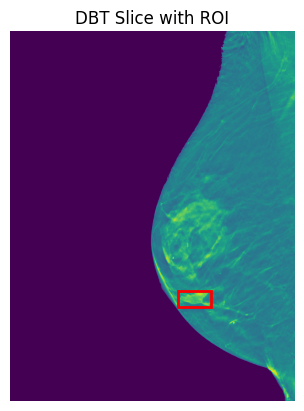

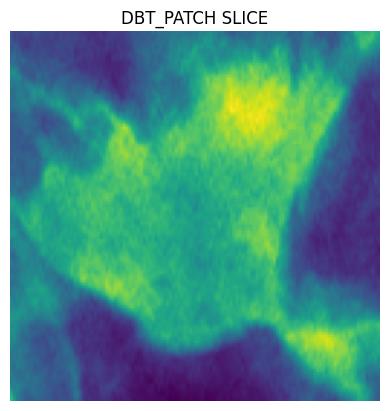

In [65]:
# visualize
from matplotlib import pyplot as plt

dbt_full = input_d["dbt_full"]
d_min, h_min, w_min, d_max, h_max, w_max = input_d["roi"]

# visualize full slice with roi
plt.imshow(input_d["dbt_full"][input_d["roi"][0]])
plt.gca().add_patch(
    plt.Rectangle(
        (w_min, h_min),
        w_max - w_min,
        h_max - h_min,
        edgecolor="red",
        facecolor="none",
        linewidth=2,
    )
)
plt.axis("off")
plt.title("DBT Slice with ROI")
plt.show()

dbt_patch = input_d["dbt_patch"]
plt.imshow(dbt_patch[input_d["roi"][0]])
plt.axis("off")
plt.title("DBT_PATCH SLICE")
plt.show()

In [66]:
from monai.transforms import (
    Compose,
    NormalizeIntensityd,
    EnsureTyped,
    RepeatChanneld,
    NormalizeIntensityd,
    ToTensord,
    ScaleIntensityd,
    Resized,
)


def get_transform(
    mean=(0.308, 0.308, 0.308),
    std=(0.2505, 0.2505, 0.2505),
    patch_size: tuple[int, int] = (128, 128),
    max_depth: int = -1,
    *args,
    **kwargs,
):

    # only use deterministic as the datast is only for evaluation purpose
    deterministic_transforms = [
        EnsureTyped(keys=["dbt_patch"], data_type="tensor"),
        Resized(keys=["dbt_patch"], spatial_size=[max_depth, *patch_size]),
        RepeatChanneld(keys=["dbt_patch"], repeats=3),
        ScaleIntensityd(keys=["dbt_patch"]),
        NormalizeIntensityd(keys=["dbt_patch"], subtrahend=mean, divisor=std, channel_wise=True),
        ToTensord(keys=["dbt_patch"]),
    ]

    return Compose(deterministic_transforms)

In [73]:
transform = get_transform()
model_input_d = transform({"dbt_patch": input_d["dbt_patch"][None, ...]})

model_input_d["dbt_patch"] = model_input_d["dbt_patch"].unsqueeze(0).to("cuda:3")
model_input_d["slice_center"] = input_d["slice_center"].unsqueeze(0).to("cuda:3")

trainer = Trainer.load_from_checkpoint("./roi_lift/ckpt/roi-lift-no-tv.ckpt", weights_only=False)
net = trainer.net.to("cuda:3")

Preparing model: RoiLift ...
<All keys matched successfully>
Loaded pretrained weights for efficientnet-b2
Loading mammo weight from /home/yjeon31/CODE/active/MammoTomo/third_party/Mammo_CLIP/src/codebase/outputs/upmc_clip/b2_detector_period_n/checkpoints/fold_0/b2-model-best-epoch-10.tar... Loaded
<All keys matched successfully>
Loaded pretrained weights for efficientnet-b2
Loading mammo weight from /home/yjeon31/CODE/active/MammoTomo/third_party/Mammo_CLIP/src/codebase/outputs/upmc_clip/b2_detector_period_n/checkpoints/fold_0/b2-model-best-epoch-10.tar... Loaded


In [77]:
output_d = net(model_input_d)

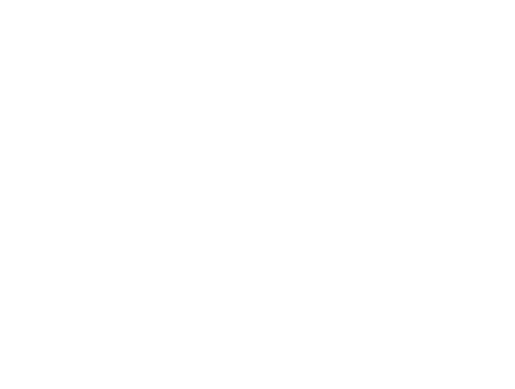

In [78]:
vis_output_d = net.vis(output_d)

vis_vol


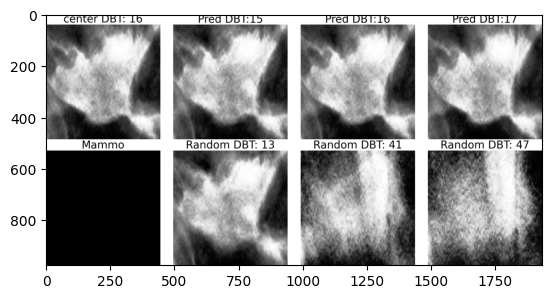

vis_slice


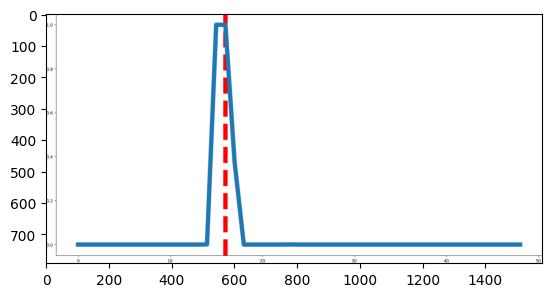

In [ ]:
for k, v in vis_output_d.items():
    print(k)
    plt.imshow(v)
    plt.show()